In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("../data/cleaned_uber.csv")

In [3]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 6371 # earth radius in km approx

    lat1, lon1, lat2, lon2 = map(
        radians,
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2 # 1. haversine formula

    c = 2 * atan2(sqrt(a), sqrt(1-a)) #current distance in radians

    return R * c

## create the distance column 

we will create the distance column in km units 

using haversine function for every row we will call harvasine and store in distance_km 

In [5]:
df["distance_km"] = df.apply(
    lambda row: haversine(
        row["pickup_latitude"],
        row["pickup_longitude"],
        row["dropoff_latitude"],
        row["dropoff_longitude"]
    ),
    axis=1
)

## check for the distance_km column

In [6]:
df[["distance_km", "fare_amount"]].head()

,distance_km,fare_amount
0,1.683323,7.5
1,2.457590,7.7
2,5.036377,12.9
3,1.661683,5.3
4,4.475450,16.0


In [7]:
df["distance_km"].describe()

count    199273.000000
mean         20.659978
std         380.717097
min           0.000000
25%           1.215430
50%           2.122079
75%           3.876555
max       16409.239135
Name: distance_km, dtype: float64

## outliers are detected 
max 16409 km very long so it is a outliter so we will analyze the distance_km column data 

look highest values fo the distance_km column

In [8]:
df['distance_km'].sort_values(ascending=False).head(10)

75575     16409.239135
138948    10321.507661
65353      8782.898606
34478      8776.106279
140117     8708.233063
164724     8681.105930
145020     8680.863938
77834      8680.851746
11497      8674.803956
40160      8671.705316
Name: distance_km, dtype: float64

## check for min values 

In [9]:
df['distance_km'].sort_values(ascending=True).head(10)

191941    0.0
149779    0.0
199236    0.0
84        0.0
148409    0.0
169570    0.0
66036     0.0
6037      0.0
6032      0.0
43677     0.0
Name: distance_km, dtype: float64

## check for total zero km rides 

Can a ride have zero distance?

Possible reasons:

Customer cancelled after booking

GPS issue

Same pickup/drop location

In [10]:
(df['distance_km'] == 0).sum()

np.int64(5614)

## invistigate the  km in detail 
check for the probability that how many uber rides are near to that km 

we will check for 90 , 95 and 99 we will take 99 is the threshhold value

In [11]:
df['distance_km'].describe(percentiles=[0.90,0.95,0.99])

count    199273.000000
mean         20.659978
std         380.717097
min           0.000000
50%           2.122079
90%           7.025025
95%          10.115126
99%          20.722118
max       16409.239135
Name: distance_km, dtype: float64

## cleaning the distance_km column using the above stacks 
only 1% of rides are above the 20km so we will take max as 50km because airport rides may have longer

and we will clean the data whic is = 0 and above 50

In [12]:
df = df[(df['distance_km'] > 0 ) & (df['distance_km'] < 50)]

now check for the data using percentiles like above 

In [13]:
df['distance_km'].describe(percentiles =[0.90,0.95,0.99])

count    193168.000000
mean          3.351720
std           3.597544
min           0.000084
50%           2.180079
90%           7.047109
95%          10.041535
99%          20.364137
max          49.003731
Name: distance_km, dtype: float64

In [14]:
df.shape

(193168, 8)

## IMPORTANT PROJECT MILESTONE

At this point:

✅ Data Cleaning Complete

✅ Distance Feature Created

✅ Distance Outliers Removed

## feature engineering on date and time 

now we will convert the date and time into hours and extract the hours now 

check for data info that date_time is in obj or datetime type

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 193168 entries, 0 to 199272
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        193168 non-null  float64
 1   pickup_datetime    193168 non-null  object 
 2   pickup_longitude   193168 non-null  float64
 3   pickup_latitude    193168 non-null  float64
 4   dropoff_longitude  193168 non-null  float64
 5   dropoff_latitude   193168 non-null  float64
 6   passenger_count    193168 non-null  int64  
 7   distance_km        193168 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 13.3+ MB


## we can see in the above it is a object so convert it into datetime type

In [16]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

## check for data type 

In [17]:
df['pickup_datetime'].dtype

datetime64[ns, UTC]

## now divide the date_time into hour , day , month , weekday 

In [18]:
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['weekday'] = df['pickup_datetime'].dt.dayofweek

In [19]:
df[['pickup_datetime','hour','day','month','weekday']].head()

,pickup_datetime,hour,day,month,weekday
0,2015-05-07 19:52:06+00:00,19,7,5,3
1,2009-07-17 20:04:56+00:00,20,17,7,4
2,2009-08-24 21:45:00+00:00,21,24,8,0
3,2009-06-26 08:22:21+00:00,8,26,6,4
4,2014-08-28 17:47:00+00:00,17,28,8,3


## remove pickup_datetime 
because it is not usefull we have converted the datetime into hour day weekday and etc.. so we will remove it 

In [20]:
df = df.drop('pickup_datetime', axis=1)

In [21]:
df.columns

Index(['fare_amount', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'passenger_count',
       'distance_km', 'hour', 'day', 'month', 'weekday'],
      dtype='object')

## Project Status

At this point:

✅ Data Cleaning Complete

✅ Distance Feature Created

✅ Time Features Created

✅ Datetime Converted and Processed

This is a major milestone.

## Next Phase: EDA (Exploratory Data Analysis)

Before training a model, we need to answer:

Questions

How is fare distributed?

How is distance distributed?

Does fare increase with distance?

Which features correlate with fare?

Are there any remaining outliers?


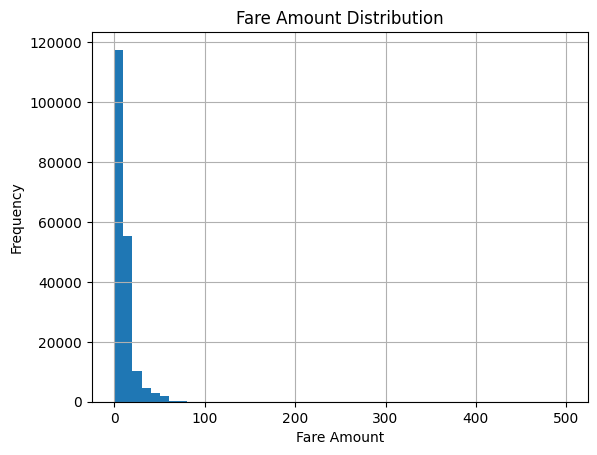

In [22]:
import matplotlib.pyplot as plt

df['fare_amount'].hist(bins=50)

plt.title('Fare Amount Distribution')
plt.xlabel('Fare Amount')
plt.ylabel('Frequency')

plt.show()

## Fare Amount Distribution

- Fare amount is positively skewed (right-skewed).
- Most rides have low fares.
- A small number of rides have very high fares.
- This suggests Uber rides are predominantly short-distance trips.

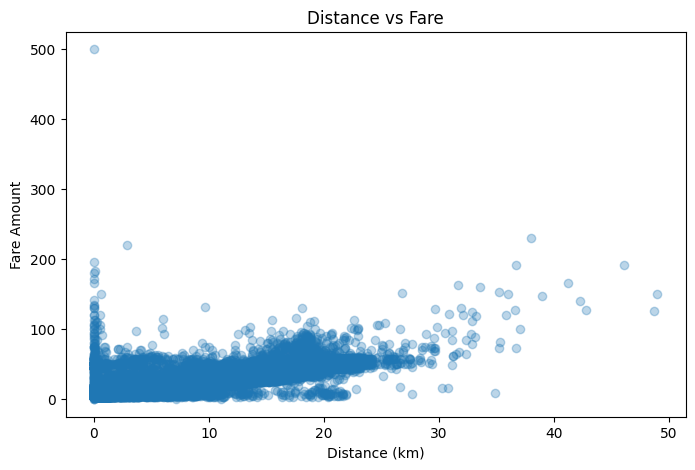

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(
    df['distance_km'],
    df['fare_amount'],
    alpha=0.3
)

plt.xlabel("Distance (km)")
plt.ylabel("Fare Amount")
plt.title("Distance vs Fare")

plt.show()

## Distance vs Fare Analysis

- Distance and fare show a positive relationship.
- As distance increases, fare generally increases.
- Distance appears to be one of the strongest predictors of fare.
- Some outliers still exist, especially rides with very low distance and unusually high fares.

## lets measure the correlation between distance and fare

In [24]:
df[['fare_amount', 'distance_km']].corr()

,fare_amount,distance_km
fare_amount,1.000000,0.868559
distance_km,0.868559,1.000000


## Business Interpretation

As:

distance_km increases

Uber fare also increases strongly.

This confirms our business assumption:

Longer rides cost more money

## Correlation Analysis

- distance_km has a strong positive correlation with fare_amount.
- Correlation value: 0.868
- This confirms that distance is one of the most important predictive features in the dataset.

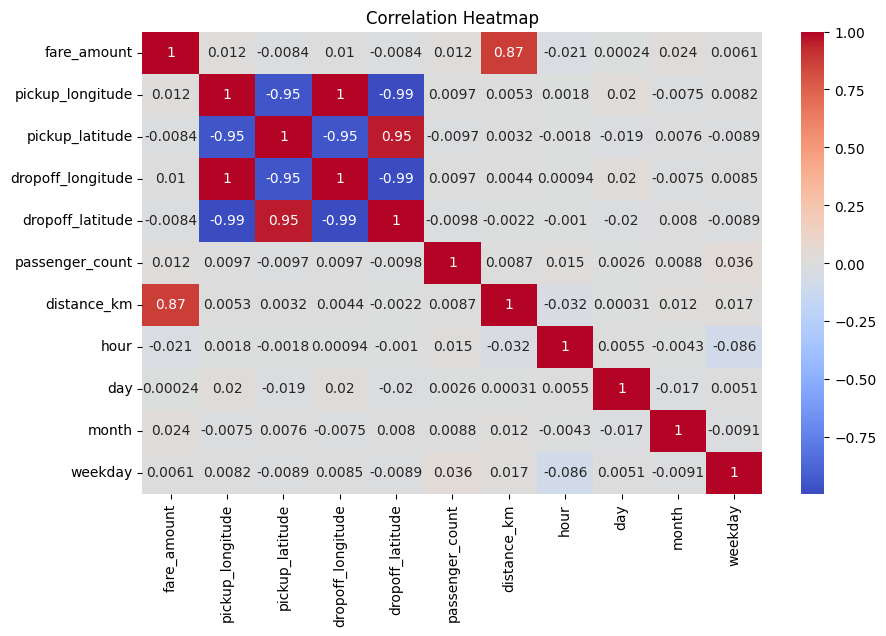

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

# EDA Summary

1. Fare amount is right-skewed.
2. Most rides have low fares.
3. Distance and fare show a strong positive relationship.
4. distance_km has the highest correlation with fare_amount (0.87).
5. Time-based features show weak linear correlation but will be retained for modeling.
6. Data is now clean and ready for machine learning.
# Correlation Analysis

Findings:

1. distance_km has a strong positive correlation (0.87) with fare_amount.
2. Distance appears to be the most important feature in the dataset.
3. Time-based features (hour, day, month, weekday) have weak individual correlations.
4. Raw GPS coordinates show little direct correlation with fare.
5. Feature engineering successfully created a highly predictive feature: distance_km.

In [26]:
df.to_csv("../data/final_uber_dataset.csv", index=False)